# code_056 · Transformations and model input contracts

**Book:** section 11.5. A self-contained preprocessing laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_11_GUIDE.md), [run evidence](../CHAPTER_11_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_056).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. Model-family comparisons and documentary contract checks retain their declared limits; there are no field-validity or universal-preprocessing claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1156;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1156


<a id="target"></a>
## Positive loads and the objective after transformation

Generate 650 independent cases with x~Uniform(-1,1) and load Y=exp(2+.8*x+Normal(0,.6)) kN. Roles are 350/100/200 for training/development/final. Compare fixed intercept/slope OLS on raw Y, OLS on log(Y) followed by exp, and the same log fit multiplied by the mean exp(training residual). The last is a training-only smearing correction; it targets a conditional mean only when its residual assumptions are suitable. All procedures are predeclared, with no policy selection. Score final MSE and MAE in kN units, plus squared log error for positive predictions; objectives can disagree. Under this known homoscedastic Gaussian-log mechanism, exp(2+.8*x) is the conditional median and exp(2+.8*x+.6**2/2) the mean. These author-known functions are construction references, not training inputs.


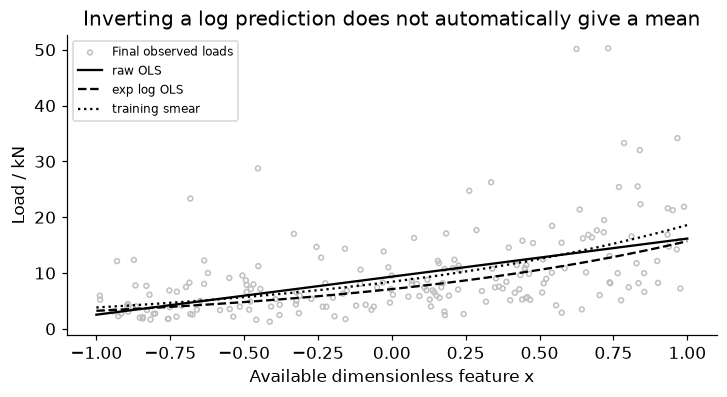

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error
from sklearn.preprocessing import PowerTransformer
x=rng.uniform(-1,1,650);X=x[:,None];Y=np.exp(2+.8*x+rng.normal(0,.6,650));tr=np.arange(350);dv=np.arange(350,450);te=np.arange(450,650)
assert np.isfinite(Y).all() and (Y>0).all()
raw=LinearRegression().fit(X[tr],Y[tr]);logfit=LinearRegression().fit(X[tr],np.log(Y[tr]));resid=np.log(Y[tr])-logfit.predict(X[tr]);smear=float(np.exp(resid).mean())
pred={'raw_OLS':raw.predict(X[te]),'exp_log_OLS':np.exp(logfit.predict(X[te])),'training_smear':smear*np.exp(logfit.predict(X[te]))};metrics={}
for name,p in pred.items():
 assert np.isfinite(p).all() and (p>0).all()
 metrics[name]={'MSE_kN2':float(mean_squared_error(Y[te],p)),'MAE_kN':float(mean_absolute_error(Y[te],p)),'mean_squared_log_error':float(np.mean((np.log(Y[te])-np.log(p))**2))}
RESULTS['final_metrics']=metrics;RESULTS['training_smearing_factor']=smear;RESULTS['generator_mean_median_ratio']=float(np.exp(.6**2/2))
grid=np.linspace(-1,1,100)[:,None];fig,ax=plt.subplots(figsize=(6.5,3.5));ax.scatter(x[te],Y[te],s=10,facecolors='none',edgecolors='.75',label='Final observed loads')
for name,p,style in [('raw OLS',raw.predict(grid),'-'),('exp log OLS',np.exp(logfit.predict(grid)),'--'),('training smear',smear*np.exp(logfit.predict(grid)),':')]:ax.plot(grid[:,0],p,color='black',ls=style,label=name)
ax.set(xlabel='Available dimensionless feature x',ylabel='Load / kN',title='Inverting a log prediction does not automatically give a mean');ax.legend(fontsize=8);plt.show()


<a id="schema"></a>
## Fit clipping and power-transform parameters only in training

A numerical demonstration learns 1st/99th percentile clipping limits and Yeo–Johnson input-transform parameters using x training values only. It checks inverse reconstruction for the invertible power transform and records how many final x values clip; clipping itself is not invertible and no claimed predictive benefit is attached. Yeo–Johnson supports zero and signed inputs; a log target requires positive values. Validation rejects a swapped unit contract, infinite input and nonpositive log target before fitting. Native missing handling would allow NaN only under its specified schema, never infinity by implication.


In [3]:
lo,hi=np.quantile(x[tr],[.01,.99]);clipped=np.clip(x[te],lo,hi);assert ((clipped>=lo)&(clipped<=hi)).all()
power=PowerTransformer(method='yeo-johnson').fit(X[tr]);Z=power.transform(X[te]);np.testing.assert_allclose(power.inverse_transform(Z),X[te],atol=1e-10)
def validate(A,unit,positive_target=None):
 if unit!='kN':raise ValueError('Expected load unit kN')
 if not np.isfinite(np.asarray(A,dtype=float)).all():raise ValueError('This schema requires finite inputs')
 if positive_target is not None and not (np.asarray(positive_target)>0).all():raise ValueError('Log target requires positive values')
rejected=0
for A,unit,t in [([1.],'N',None),([np.inf],'kN',None),([1.],'kN',[0.])]:
 try:validate(A,unit,t)
 except ValueError:rejected+=1
assert rejected==3
RESULTS['training_clip_limits']=[float(lo),float(hi)];RESULTS['final_clipped_cases']=int(np.sum(clipped!=x[te]));RESULTS['power_lambda']=power.lambdas_.tolist();RESULTS['schema_violations_rejected']=rejected


<a id="contracts"></a>
## A documentary contract review is different from executing a foundation model

Primary maintainer README inspected on 19 October 2026 at PriorLabs/TabPFN commit `417c9877dbfe657afdbe0aee70af2a05ffe4abba`: [immutable source](https://github.com/PriorLabs/TabPFN/blob/417c9877dbfe657afdbe0aee70af2a05ffe4abba/README.md). It identifies TabPFN-3.5 as default, supports missing values, and advises against external scaling/one-hot encoding. First use downloads a checkpoint; weight access and licensing are separate from this offline lab. Inspect the installed package, selected checkpoint, categorical dtypes/indices, supported dimensions and internal preprocessing before use. This notebook does not install, download or run TabPFN, and reports no foundation-model accuracy or validated acceptance test.

The schematic contrasts model-specific handling of the same valid input table. It records a documentation review, not a replacement runtime implementation. Foundation-model input support does not establish correct units, available information or valid targets. Missing is still distinct from source corruption.


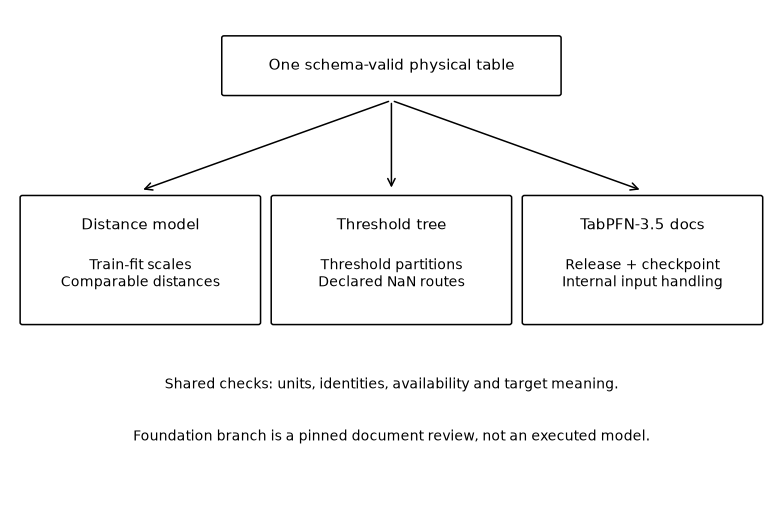

In [4]:
from matplotlib.patches import FancyBboxPatch,FancyArrowPatch
fig,ax=plt.subplots(figsize=(7,4.5));ax.axis('off');ax.set(xlim=(0,10),ylim=(0,7))
ax.add_patch(FancyBboxPatch((2.8,5.8),4.4,.8,boxstyle='round,pad=.03',fc='white'));ax.text(5,6.2,'One schema-valid physical table',ha='center',va='center',fontsize=10)
for center,title,body in [(1.7,'Distance model','Train-fit scales'+chr(10)+'Comparable distances'),(5,'Threshold tree','Threshold partitions'+chr(10)+'Declared NaN routes'),(8.3,'TabPFN-3.5 docs','Release + checkpoint'+chr(10)+'Internal input handling')]:
 ax.add_patch(FancyBboxPatch((center-1.55,2.5),3.1,1.8,boxstyle='round,pad=.03',fc='white'));ax.text(center,3.9,title,ha='center',va='center',fontsize=10);ax.text(center,3.2,body,ha='center',va='center',fontsize=9);ax.add_patch(FancyArrowPatch((5,5.7),(center,4.4),arrowstyle='->',mutation_scale=12))
ax.text(5,1.55,'Shared checks: units, identities, availability and target meaning.',ha='center',fontsize=9);ax.text(5,.8,'Foundation branch is a pinned document review, not an executed model.',ha='center',fontsize=9);plt.show()
RESULTS['foundation_contract_document']={'repository':'PriorLabs/TabPFN','commit':'417c9877dbfe657afdbe0aee70af2a05ffe4abba','documented_default':'TabPFN-3.5','runtime_executed':False};RESULTS['power_inverse_round_trip_passed']=True


In [5]:
summary={'example_id':'code_056','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['log-target estimands and inverse-transform bias', 'training-residual smearing and original-unit scoring', 'clipping and power-transform state', 'release-pinned documentary input contract'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["log-target estimands and inverse-transform bias", "training-residual smearing and original-unit scoring", "clipping and power-transform state", "release-pinned documentary input contract"], "elapsed_seconds": 0.236, "example_id": "code_056", "hardware": "Darwin arm64 CPU", "results": {"final_clipped_cases": 6, "final_metrics": {"exp_log_OLS": {"MAE_kN": 4.073622155440274, "MSE_kN2": 43.502081606698766, "mean_squared_log_error": 0.3376046566036368}, "raw_OLS": {"MAE_kN": 4.413402016889815, "MSE_kN2": 42.78936101246356, "mean_squared_log_error": 0.3834079183542199}, "training_smear": {"MAE_kN": 4.283623476092593, "MSE_kN2": 41.308347106320205, "mean_squared_log_error": 0.3612742259859485}}, "foundation_contract_document": {"commit": "417c9877dbfe657afdbe0aee70af2a05ffe4abba", "documented_default": "TabPFN-3.5", "repository": "PriorLabs/TabPFN", "runtime_executed": false}, "generator_mean_median_ratio": 1.1972173631218102, "power_inverse_